<a href="https://colab.research.google.com/github/syifahumaira17/simuteh-2330511079/blob/main/P5_tepi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!git clone https://github.com/syifahumaira17/simuteh-2330511079.git


Cloning into 'simuteh-2330511079'...
remote: Enumerating objects: 356, done.
remote: Counting objects: 100% (118/118), done.
remote: Compressing objects: 100% (109/109), done.
remote: Total 356 (delta 40), reused 43 (delta 8), pack-reused 238 (from 1)
Receiving objects: 100% (356/356), 81.51 MiB | 25.79 MiB/s, done.
Resolving deltas: 100% (51/51), done.


In [2]:

import os

folder = "/content/simuteh-2330511079"

print("Isi repository:")
print(os.listdir(folder))

print("\nIsi folder src:")
print(os.listdir(folder + "/src"))

print("\nIsi folder hasil:")
print(os.listdir(folder + "/hasil"))

print("\nIsi folder data/sintetis:")
print(os.listdir(folder + "/data/sintetis"))


Isi repository:
['hasil', 'requirements.txt', '.git', '.gitignore', 'laporan', 'notebook', 'README.md', 'data', 'src']

Isi folder src:
['praproses.py', 'utils_cv.py', 'bercak.py', 'buat_dataset_sintetis.py', 'utils_tepi.py']

Isi folder hasil:
['b4_crop_bercak_median.png', 'b1_pipeline.png', 'p5_f1_kondisi.png', 'b1_bgr_rgb.png', 'param_praproses.json', 'p6_scatter_komponen.csv', 'p6_eksperimen_se.csv', 'p6_kesalahan_2.png', 'b5_ringkasan_kb.csv', 'b4_grafik_kb_median.png', 'b4_eksperimen_median.csv', 'b5_kb_40_citra.csv', 'b5_pipeline_final.png', 'b4_urutan_denoise_sharpen.png', 'b4_crop_median.png', 'p6_kesalahan_1.png', 'p5_tabel_tepi.csv', 'p5_tabel7_canny.csv', 'p6_tabel11_filter.csv', 'b4_pengujian_kernel_median.csv', 'p5_canny_sigma_ambang.csv', 'b5_perbandingan_citra_sehat.png', 'b4_tabel_penapis.csv', 'param_bercak.json', 'p5_canny_persentil.csv', 'b3_tabel_kb_metode.csv', 'p6_scatter_evaluasi.png', 'b5_ringkasan_citra_sehat.csv', 'b5_uji_20_citra_sehat.csv', 'b4_grafik_di_me

In [3]:

import os

folder = "/content/simuteh-2330511079"

file_penting = [
    "src/praproses.py",
    "src/utils_cv.py",
    "hasil/param_praproses.json",
    "data/sintetis/label.csv"
]

for file in file_penting:
    path = os.path.join(folder, file)
    print(file, "=>", "ADA" if os.path.exists(path) else "TIDAK ADA")


src/praproses.py => ADA
src/utils_cv.py => ADA
hasil/param_praproses.json => ADA
data/sintetis/label.csv => ADA


In [4]:

import sys
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("/content/simuteh-2330511079/src")

from utils_cv import baca, tampil
from praproses import praproses

# Mengatur tampilan tabel
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

# Memuat parameter praproses dan label dataset
BASE = "/content/simuteh-2330511079"

with open(f"{BASE}/hasil/param_praproses.json") as f:
    PARAM = json.load(f)

label = pd.read_csv(f"{BASE}/data/sintetis/label.csv")

print("Jumlah data:", len(label))
print("\nKolom label:")
print(label.columns.tolist())

display(label.head())


Jumlah data: 60

Kolom label:
['nama_file', 'kelas', 'kondisi_cahaya', 'persen_bercak']


,nama_file,kelas,kondisi_cahaya,persen_bercak
0,teh_001.png,sehat,normal,0.0
1,teh_002.png,sehat,gelap,0.0
2,teh_003.png,sehat,terang,0.0
3,teh_004.png,sehat,kontras_rendah,0.0
4,teh_005.png,sehat,bayangan,0.0


In [5]:

%%writefile /content/simuteh-2330511079/src/utils_tepi.py

"""utils_tepi.py: fungsi bantu evaluasi deteksi tepi dan morfologi P5-P6."""

import cv2
import numpy as np


def tepi_acuan(mask):
    """Tepi acuan selebar 1 piksel dari sebuah mask biner."""
    m = (mask > 0).astype(np.uint8)
    return ((m - cv2.erode(m, np.ones((3, 3), np.uint8))) > 0).astype(np.uint8) * 255


def skor_tepi(prediksi, acuan, toleransi=2):
    """Menghitung presisi, recall, dan F1 tepi."""
    p = prediksi > 0
    a = acuan > 0

    if p.sum() == 0 or a.sum() == 0:
        return 0.0, 0.0, 0.0

    jarak_ke_a = cv2.distanceTransform((~a).astype(np.uint8), cv2.DIST_L2, 3)
    jarak_ke_p = cv2.distanceTransform((~p).astype(np.uint8), cv2.DIST_L2, 3)

    presisi = float((jarak_ke_a[p] <= toleransi).mean())
    recall = float((jarak_ke_p[a] <= toleransi).mean())

    f1 = 0.0 if presisi + recall == 0 else 2 * presisi * recall / (presisi + recall)

    return round(presisi, 3), round(recall, 3), round(f1, 3)


def iou(a, b):
    """Intersection over Union dua mask biner."""
    a, b = a > 0, b > 0
    gabungan = (a | b).sum()
    return 1.0 if gabungan == 0 else float((a & b).sum() / gabungan)


def mask_daun_awal(img_bgr):
    """Mask daun sementara menggunakan ambang Otsu pada kanal saturasi."""
    s = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 1]
    _, m = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return m


def bercak_awal(img_bgr, mask_daun, kanal=2, k=4.0):
    """Mask bercak sementara berdasarkan median dan MAD."""
    c = img_bgr[:, :, kanal].astype(np.float32)
    m = mask_daun > 0

    med = np.median(c[m])
    mad = 1.4826 * np.median(np.abs(c[m] - med))

    return (((c > med + k * mad) & m) * 255).astype(np.uint8)


Overwriting /content/simuteh-2330511079/src/utils_tepi.py


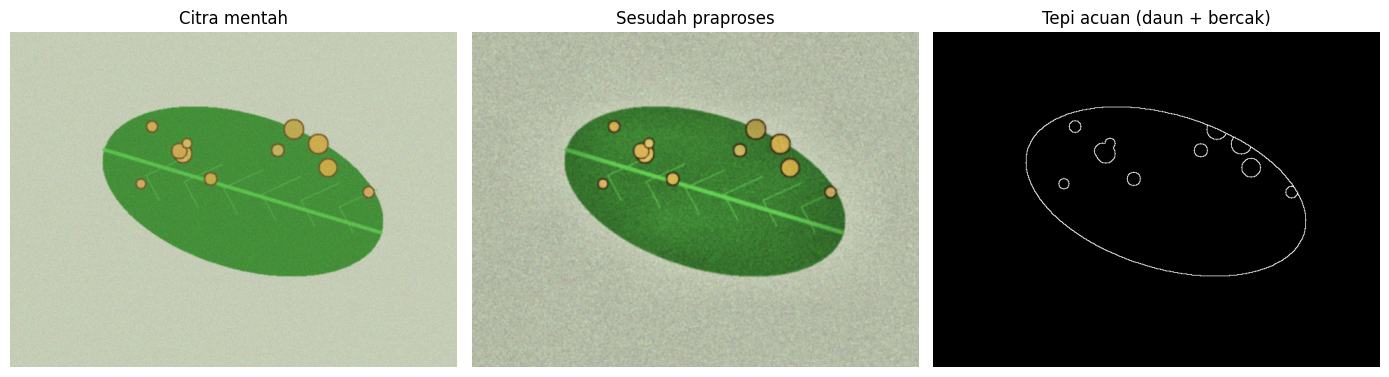

In [6]:

# Memastikan folder src bisa dibaca
import sys
sys.path.insert(0, "/content/simuteh-2330511079/src")

import cv2
import numpy as np
import matplotlib.pyplot as plt

from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan

# Lokasi dataset
BASE = "/content/simuteh-2330511079"

# Membaca parameter praproses
import json
with open(f"{BASE}/hasil/param_praproses.json", "r") as f:
    PARAM = json.load(f)

# Fungsi untuk memuat citra dan mask
def muat(nama):
    img = baca(f"{BASE}/data/sintetis/citra/{nama}")
    md = cv2.imread(f"{BASE}/data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"{BASE}/data/sintetis/mask_bercak/{nama}", 0)

    return img, md, mb

# Mengambil satu contoh citra
img, md, mb = muat("teh_041.png")

# Melakukan praproses
pra = praproses(img, PARAM)

# Membuat tepi acuan dari mask daun dan bercak
acuan = cv2.bitwise_or(
    tepi_acuan(md),
    tepi_acuan(mb)
)

# Menampilkan hasil
tampil(
    [img, pra, acuan],
    [
        "Citra mentah",
        "Sesudah praproses",
        "Tepi acuan (daun + bercak)"
    ]
)


Selisih maks gx manual vs cv2.Sobel: 0.0
Magnitudo maks: 573.1


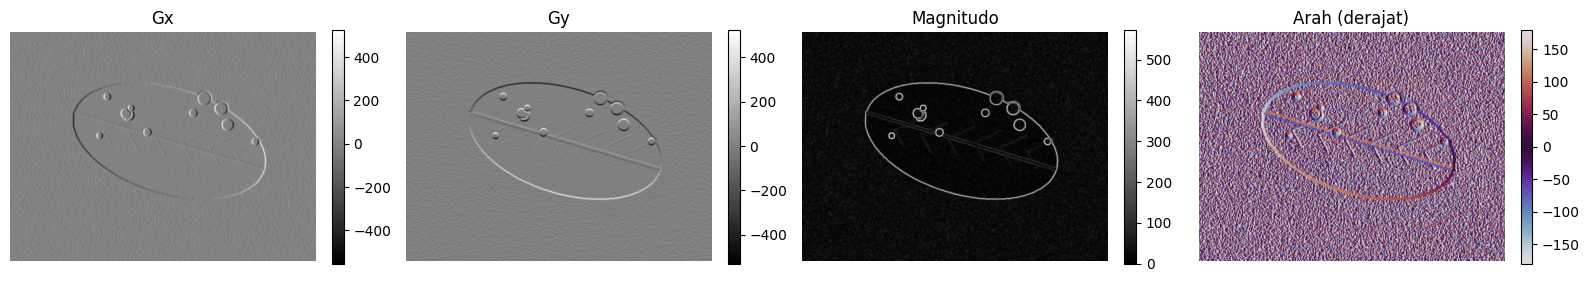

In [7]:

# KODE 1.2 - GRADIEN SOBEL MANUAL

# Mengambil kanal R dari hasil praproses
g = pra[:, :, 2].astype(np.float32)

# Kernel Sobel
kx = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], np.float32)

ky = kx.T

# Menghitung gradien arah X dan Y
gx = cv2.filter2D(g, cv2.CV_32F, kx)
gy = cv2.filter2D(g, cv2.CV_32F, ky)

# Menghitung magnitudo dan arah gradien
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# Membandingkan dengan fungsi Sobel OpenCV
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)

print(
    "Selisih maks gx manual vs cv2.Sobel:",
    np.abs(gx - gx_cv).max()
)

print("Magnitudo maks:", mag.max().round(1))

# Menampilkan hasil
plt.figure(figsize=(16, 3.6))

for i, (c, jd) in enumerate([
    (gx, "Gx"),
    (gy, "Gy"),
    (mag, "Magnitudo"),
    (arah, "Arah (derajat)")
]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd)
    plt.axis("off")
    plt.colorbar(fraction=0.035)

plt.tight_layout()
plt.show()


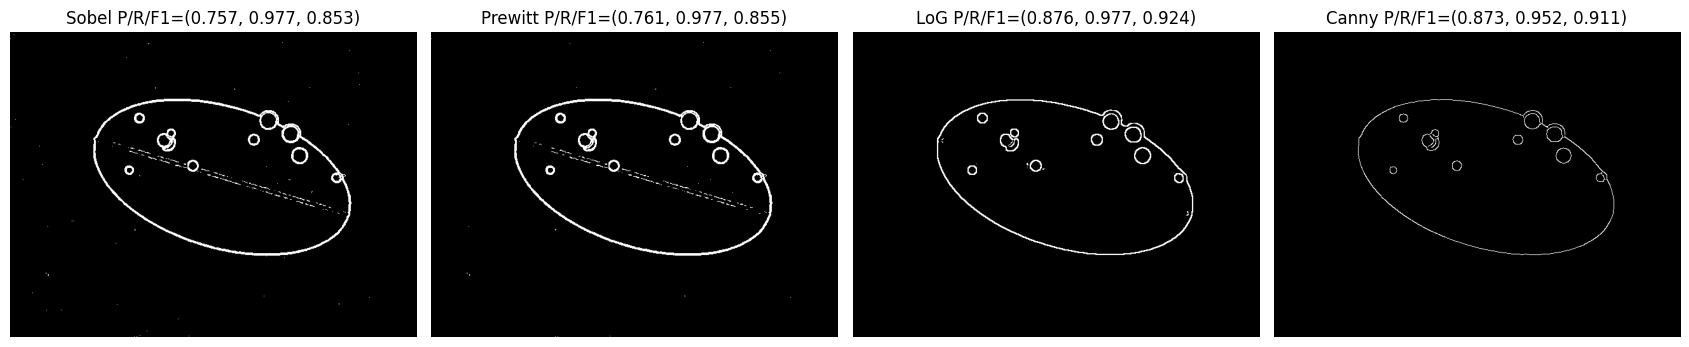

In [8]:

# KODE 1.3 - FUNGSI SOBEL, PREWITT, LoG, DAN CANNY

from utils_tepi import skor_tepi

# 1. Operator Sobel
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(
        cv2.Sobel(g, cv2.CV_32F, 1, 0),
        cv2.Sobel(g, cv2.CV_32F, 0, 1)
    )
    return ((m > T) * 255).astype(np.uint8)


# 2. Operator Prewitt
def tepi_prewitt(g, T=75):
    kx = np.array([
        [-1, 0, 1],
        [-1, 0, 1],
        [-1, 0, 1]
    ], np.float32)

    g = g.astype(np.float32)

    m = np.hypot(
        cv2.filter2D(g, -1, kx),
        cv2.filter2D(g, -1, kx.T)
    )

    return ((m > T) * 255).astype(np.uint8)


# 3. Operator Laplacian of Gaussian (LoG)
def tepi_log(g, sigma=3.0, frac=0.2):
    L = cv2.Laplacian(
        cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma),
        cv2.CV_32F
    )

    mn = cv2.erode(L, np.ones((3, 3), np.uint8))
    mx = cv2.dilate(L, np.ones((3, 3), np.uint8))

    return (
        (
            (mn < 0) &
            (mx > 0) &
            (mx - mn > frac * np.abs(L).max())
        ) * 255
    ).astype(np.uint8)


# 4. Operator Canny
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)

    return cv2.Canny(g, lo, hi)


# Menggabungkan metode deteksi tepi
metode = {
    "Sobel": tepi_sobel,
    "Prewitt": tepi_prewitt,
    "LoG": tepi_log,
    "Canny": tepi_canny
}

# Menggunakan kanal R hasil praproses
g = pra[:, :, 2]

# Menjalankan setiap metode
hasil = {
    nm: f(g)
    for nm, f in metode.items()
}

# Menampilkan hasil dan nilai Precision, Recall, F1
tampil(
    list(hasil.values()),
    [
        f"{nm} P/R/F1={skor_tepi(e, acuan)}"
        for nm, e in hasil.items()
    ],
    ukuran=(17, 3.6)
)


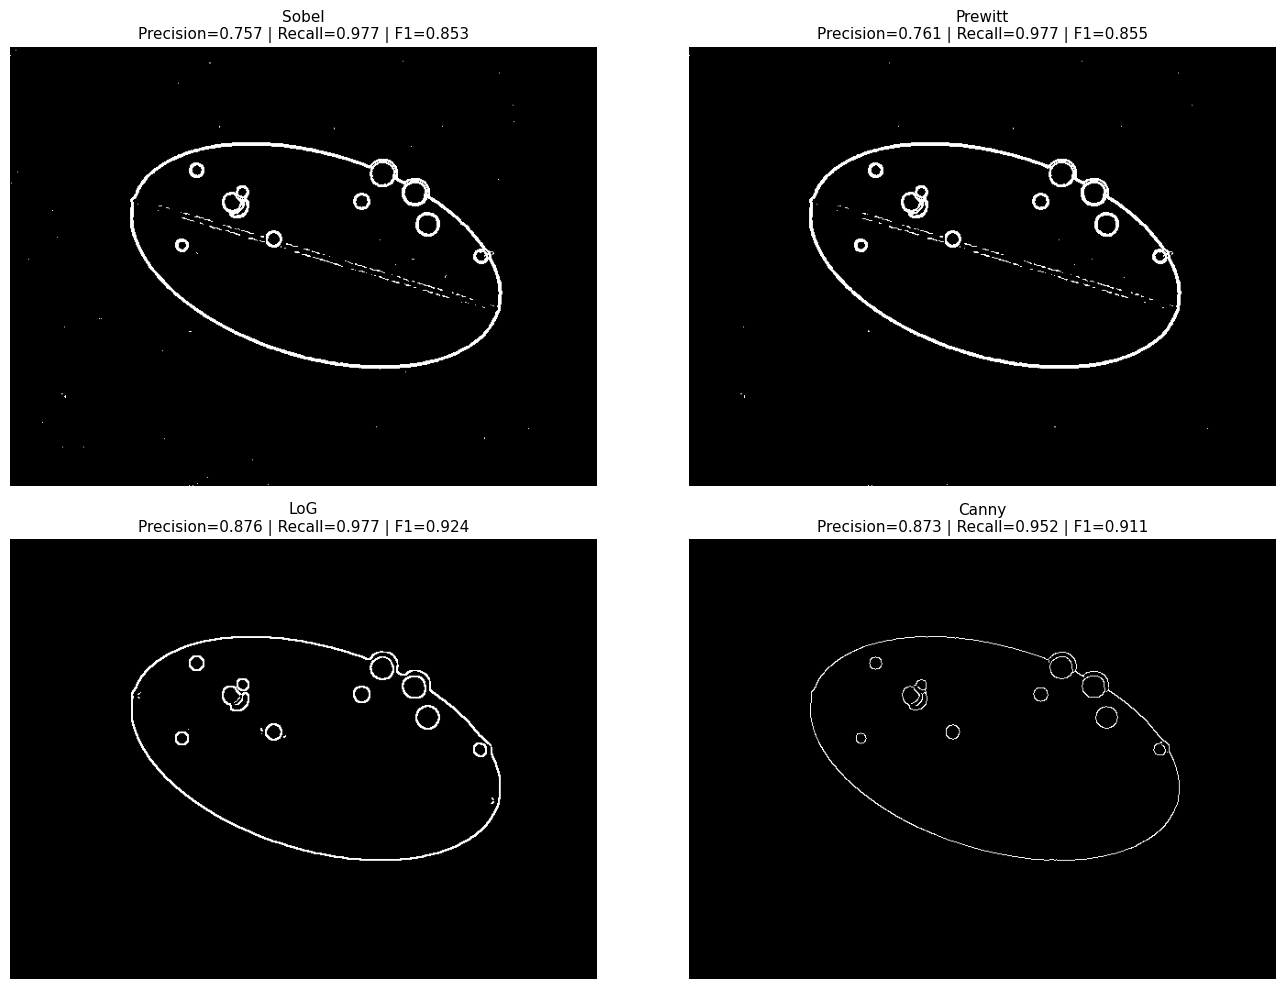

In [9]:

plt.figure(figsize=(14, 10))

for i, (nama, citra) in enumerate(hasil.items()):
    # Menghitung Precision, Recall, dan F1
    p, r, f1 = skor_tepi(citra, acuan)

    plt.subplot(2, 2, i + 1)
    plt.imshow(citra, cmap="gray", vmin=0, vmax=255)
    plt.title(
        f"{nama}\nPrecision={p} | Recall={r} | F1={f1}",
        fontsize=11
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


In [10]:

# KODE 1.4 - EVALUASI 40 CITRA BERBERCAK

baris = []

# Menguji seluruh citra selain kelas sehat
for _, d in label[label.kelas != "sehat"].iterrows():

    img, md, mb = muat(d.nama_file)

    # Membuat tepi acuan
    ac = cv2.bitwise_or(
        tepi_acuan(md),
        tepi_acuan(mb)
    )

    # Membandingkan citra mentah dan hasil praproses
    for sumber, im in [
        ("mentah", img),
        ("praproses", praproses(img, PARAM))
    ]:

        # Membandingkan kanal Gray dan R
        for kanal, g in [
            ("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)),
            ("R", im[:, :, 2])
        ]:

            # Menguji empat operator
            for nm, f in metode.items():

                p, r, f1 = skor_tepi(f(g), ac)

                baris.append([
                    d.kondisi_cahaya,
                    sumber,
                    kanal,
                    nm,
                    p,
                    r,
                    f1
                ])

# Membuat tabel hasil evaluasi
tabel_tepi = pd.DataFrame(
    baris,
    columns=[
        "kondisi",
        "sumber",
        "kanal",
        "metode",
        "P",
        "R",
        "F1"
    ]
)

# Menghitung nilai rata-rata
ringkas = (
    tabel_tepi
    .groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]]
    .mean()
    .round(3)
)

print("Jumlah pengujian:", len(label[label.kelas != "sehat"]))
print("\nHASIL RATA-RATA EVALUASI:")
display(ringkas)

# Menyimpan hasil ke CSV
tabel_tepi.to_csv(
    f"{BASE}/hasil/p5_tabel_tepi.csv",
    index=False
)

print("\nFile berhasil disimpan:")
print(f"{BASE}/hasil/p5_tabel_tepi.csv")


Jumlah pengujian: 40

HASIL RATA-RATA EVALUASI:


P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.735  0.748  0.739
                LoG      0.606  0.997  0.746
                Prewitt  0.801  0.969  0.868
                Sobel    0.770  0.975  0.850
          R     Canny    0.984  0.986  0.985
                LoG      0.888  0.997  0.927
                Prewitt  0.560  0.996  0.671
                Sobel    0.491  0.996  0.606
praproses Gray  Canny    0.667  0.943  0.775
                LoG      0.523  0.997  0.675
                Prewitt  0.559  0.997  0.708
                Sobel    0.524  0.997  0.676
          R     Canny    0.948  0.989  0.966
                LoG      0.817  0.998  0.879
                Prewitt  0.437  0.998  0.573
                Sobel    0.390  0.998  0.526


File berhasil disimpan:
/content/simuteh-2330511079/hasil/p5_tabel_tepi.csv


<Figure size 1000x600 with 0 Axes>

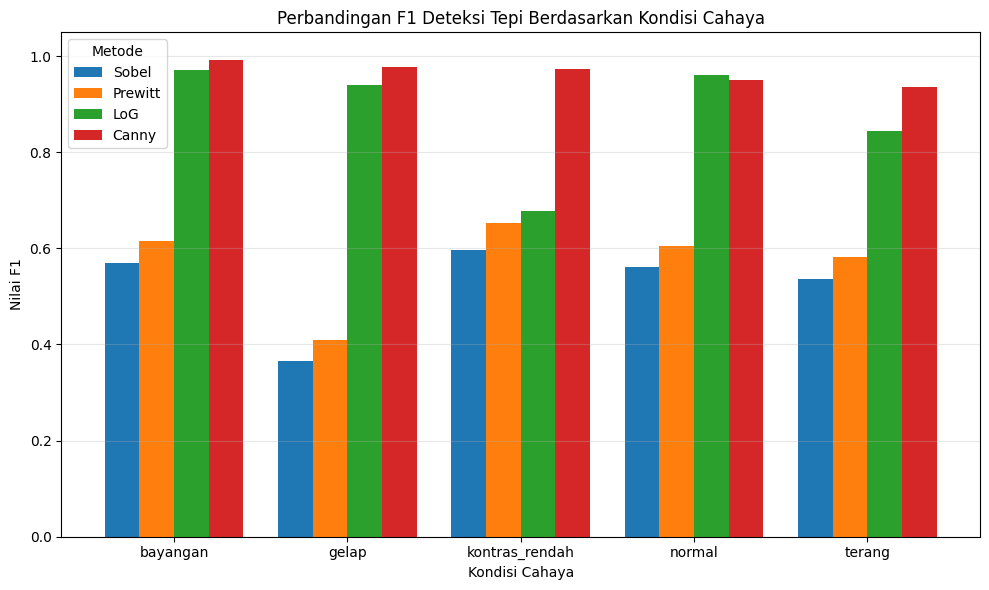

Grafik berhasil disimpan di folder hasil.


In [11]:

# KODE 1.5 - GRAFIK F1 BERDASARKAN KONDISI CAHAYA

# Mengambil data praproses, kanal R
data_grafik = tabel_tepi[
    (tabel_tepi["sumber"] == "praproses") &
    (tabel_tepi["kanal"] == "R")
]

# Membuat tabel F1 berdasarkan kondisi cahaya dan metode
grafik_f1 = data_grafik.pivot_table(
    index="kondisi",
    columns="metode",
    values="F1",
    aggfunc="mean"
)

# Mengatur urutan operator
urutan = ["Sobel", "Prewitt", "LoG", "Canny"]
grafik_f1 = grafik_f1[urutan]

# Menampilkan grafik
plt.figure(figsize=(10, 6))

grafik_f1.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Perbandingan F1 Deteksi Tepi Berdasarkan Kondisi Cahaya")
plt.xlabel("Kondisi Cahaya")
plt.ylabel("Nilai F1")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Metode")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Menyimpan grafik
plt.savefig(
    f"{BASE}/hasil/p5_f1_kondisi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grafik berhasil disimpan di folder hasil.")


In [12]:

# KODE 2.1 - EKSPERIMEN SIGMA DAN AMBANG CANNY

baris = []

for _, d in label[label.kelas != "sehat"].iterrows():

    img, md, mb = muat(d.nama_file)

    # Citra hasil praproses, kanal R
    g = praproses(img, PARAM)[:, :, 2]

    # Tepi acuan daun dan bercak
    ad = tepi_acuan(md)
    ab = tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)

    # Menguji 9 kombinasi sigma dan ambang
    for sigma in [0, 1.0, 2.0]:

        for lo, hi in [(30, 90), (50, 150), (100, 200)]:

            e = tepi_canny(g, lo, hi, sigma)

            p, r, f1 = skor_tepi(e, ac)

            # Recall khusus tepi bercak
            r_bercak = skor_tepi(e, ab)[1]

            baris.append([
                d.kelas,
                sigma,
                f"{lo}/{hi}",
                p,
                r,
                f1,
                r_bercak
            ])

# Membuat DataFrame hasil pengujian
canny = pd.DataFrame(
    baris,
    columns=[
        "kelas",
        "sigma",
        "ambang",
        "P",
        "R",
        "F1",
        "R_bercak"
    ]
)

# Rata-rata hasil setiap kombinasi
print("RATA-RATA HASIL PENGUJIAN:")
display(
    canny.groupby(["sigma", "ambang"])[
        ["P", "R", "F1", "R_bercak"]
    ].mean().round(3)
)

# Recall bercak berdasarkan kelas
print("RECALL BERCAK BERDASARKAN KELAS:")
display(
    canny.pivot_table(
        index=["sigma", "ambang"],
        columns="kelas",
        values="R_bercak"
    ).round(3)
)

# Simpan hasil pengujian
canny.to_csv(
    f"{BASE}/hasil/p5_canny_sigma_ambang.csv",
    index=False
)

print("Hasil berhasil disimpan.")


RATA-RATA HASIL PENGUJIAN:


P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.498  0.994  0.605     0.977
      30/90    0.020  0.997  0.038     0.987
      50/150   0.110  0.995  0.169     0.981
1.0   100/200  0.975  0.993  0.984     0.970
      30/90    0.206  0.994  0.296     0.974
      50/150   0.873  0.994  0.920     0.971
2.0   100/200  0.789  0.788  0.788     0.716
      30/90    0.948  0.989  0.966     0.958
      50/150   0.979  0.980  0.979     0.875

RECALL BERCAK BERDASARKAN KELAS:


kelas          berat  ringan
sigma ambang                
0.0   100/200  0.976   0.978
      30/90    0.992   0.983
      50/150   0.983   0.980
1.0   100/200  0.974   0.967
      30/90    0.976   0.972
      50/150   0.974   0.968
2.0   100/200  0.753   0.679
      30/90    0.948   0.969
      50/150   0.917   0.834

Hasil berhasil disimpan.


In [13]:

# Menggabungkan hasil rata-rata dan recall bercak per kelas

rata = (
    canny.groupby(["sigma", "ambang"])[["P", "R", "F1"]]
    .mean()
    .round(3)
)

bercak = (
    canny.pivot_table(
        index=["sigma", "ambang"],
        columns="kelas",
        values="R_bercak"
    )
    .round(3)
)

tabel7 = rata.join(bercak)

# Menampilkan tabel lengkap
display(tabel7)

# Menyimpan tabel
tabel7.to_csv(
    f"{BASE}/hasil/p5_tabel7_canny.csv"
)

print("Tabel 7 berhasil disimpan.")


P      R     F1  berat  ringan
sigma ambang                                     
0.0   100/200  0.498  0.994  0.605  0.976   0.978
      30/90    0.020  0.997  0.038  0.992   0.983
      50/150   0.110  0.995  0.169  0.983   0.980
1.0   100/200  0.975  0.993  0.984  0.974   0.967
      30/90    0.206  0.994  0.296  0.976   0.972
      50/150   0.873  0.994  0.920  0.974   0.968
2.0   100/200  0.789  0.788  0.788  0.753   0.679
      30/90    0.948  0.989  0.966  0.948   0.969
      50/150   0.979  0.980  0.979  0.917   0.834

Tabel 7 berhasil disimpan.


In [14]:

# KODE 2.2 - AMBANG CANNY OTOMATIS BERBASIS MEDIAN

def canny_otomatis(g, s=0.33):
    """
    Ambang dari median intensitas:
    bawah = (1-s) x median
    atas = (1+s) x median
    """
    v = np.median(g)

    return cv2.Canny(
        g,
        int(max(0, (1 - s) * v)),
        int(min(255, (1 + s) * v))
    )


baris = []

for _, d in label[label.kelas != "sehat"].iterrows():

    img, md, mb = muat(d.nama_file)

    # Membuat tepi acuan
    ac = cv2.bitwise_or(
        tepi_acuan(md),
        tepi_acuan(mb)
    )

    # Melakukan praproses
    pra_ = praproses(img, PARAM)

    # Membandingkan kanal Gray dan R
    for kanal, g in [
        ("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)),
        ("R", pra_[:, :, 2])
    ]:

        # Canny dengan ambang otomatis
        baris.append([
            d.kondisi_cahaya,
            kanal,
            "otomatis",
            skor_tepi(canny_otomatis(g), ac)[2],
            np.median(g)
        ])

        # Canny dengan ambang tetap 30/90
        baris.append([
            d.kondisi_cahaya,
            kanal,
            "tetap 30/90",
            skor_tepi(tepi_canny(g), ac)[2],
            np.median(g)
        ])


# Membuat tabel hasil
auto = pd.DataFrame(
    baris,
    columns=[
        "kondisi",
        "kanal",
        "ambang",
        "F1",
        "median"
    ]
)

# Menampilkan perbandingan F1
print("PERBANDINGAN F1 AMBANG OTOMATIS DAN TETAP:")

display(
    auto.pivot_table(
        index=["kanal", "ambang"],
        columns="kondisi",
        values="F1"
    ).round(3)
)

# Menampilkan median intensitas
print("RATA-RATA MEDIAN INTENSITAS:")

display(
    auto.groupby(["kanal", "kondisi"])["median"]
    .mean()
    .round(1)
)


PERBANDINGAN F1 AMBANG OTOMATIS DAN TETAP:


kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.523  0.535           0.792   0.735   0.837
      tetap 30/90     0.759  0.725           0.910   0.735   0.748
R     otomatis        0.388  0.352           0.762   0.824   0.914
      tetap 30/90     0.992  0.977           0.973   0.950   0.937

RATA-RATA MEDIAN INTENSITAS:


kanal  kondisi       
Gray   bayangan          116.1
       gelap             131.9
       kontras_rendah    149.5
       normal            170.5
       terang            193.6
R      bayangan          123.2
       gelap             147.2
       kontras_rendah    151.8
       normal            177.2
       terang            197.9
Name: median, dtype: float64

In [15]:

def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    # 1. Menghaluskan citra dengan Gaussian
    halus = cv2.GaussianBlur(
        g, (0, 0), sigma
    )

    # 2. Menghitung magnitudo Sobel
    gx = cv2.Sobel(
        halus, cv2.CV_32F, 1, 0, ksize=3
    )
    gy = cv2.Sobel(
        halus, cv2.CV_32F, 0, 1, ksize=3
    )

    magnitudo = np.sqrt(gx**2 + gy**2)

    # 3. Menghitung ambang berdasarkan persentil
    ambang_atas = np.percentile(magnitudo, q)
    ambang_bawah = rasio * ambang_atas

    # 4. Deteksi tepi Canny
    tepi = cv2.Canny(
        halus,
        int(ambang_bawah),
        int(ambang_atas)
    )

    return tepi


# Pengujian persentil 90, 95, dan 98
baris_persentil = []

for _, d in label[label.kelas != "sehat"].iterrows():

    img, md, mb = muat(d.nama_file)

    ac = cv2.bitwise_or(
        tepi_acuan(md),
        tepi_acuan(mb)
    )

    pra_ = praproses(img, PARAM)

    for kanal, g in [
        ("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)),
        ("R", pra_[:, :, 2])
    ]:

        for q in [90, 95, 98]:

            e = canny_persentil(g, q)

            p, r, f1 = skor_tepi(e, ac)

            baris_persentil.append([
                d.kondisi_cahaya,
                kanal,
                q,
                p,
                r,
                f1
            ])


tabel_persentil = pd.DataFrame(
    baris_persentil,
    columns=[
        "kondisi",
        "kanal",
        "q",
        "P",
        "R",
        "F1"
    ]
)

# Rata-rata F1 berdasarkan kanal, persentil, dan kondisi cahaya
hasil_persentil = tabel_persentil.pivot_table(
    index=["kanal", "q"],
    columns="kondisi",
    values="F1"
).round(3)

display(hasil_persentil)

# Simpan hasil
tabel_persentil.to_csv(
    f"{BASE}/hasil/p5_canny_persentil.csv",
    index=False
)


kondisi   bayangan  gelap  kontras_rendah  normal  terang
kanal q                                                  
Gray  90     0.062  0.058           0.055   0.064   0.057
      95     0.292  0.251           0.107   0.387   0.232
      98     0.754  0.726           0.713   0.736   0.754
R     90     0.069  0.062           0.054   0.069   0.059
      95     0.144  0.083           0.089   0.334   0.226
      98     0.969  0.978           0.833   0.979   0.861

In [16]:
%cd /content/simuteh-2330511079
!git status

/content/simuteh-2330511079
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


kanal,Gray,R
kondisi,,
bayangan,864.8,0.0
gelap,891.0,0.0
kontras_rendah,14.8,0.0
normal,887.2,87.5
terang,918.2,75.2


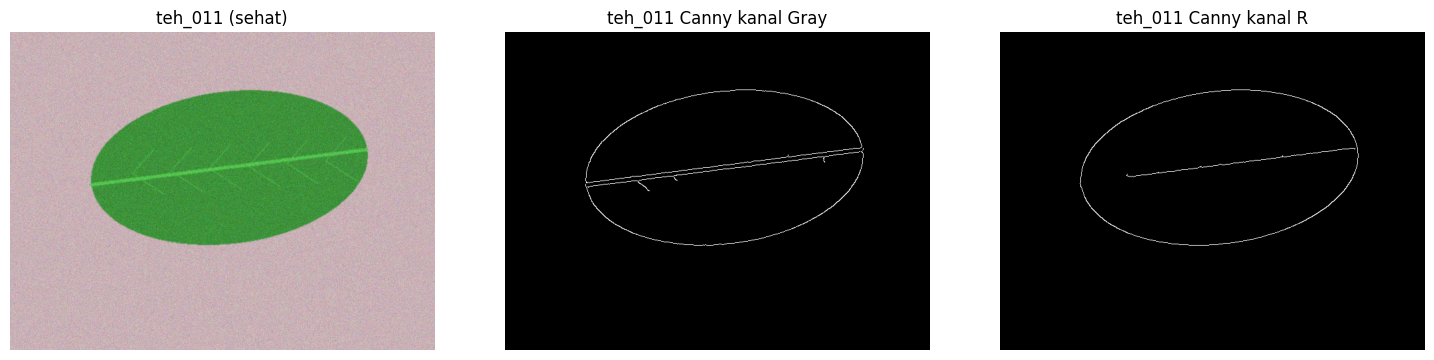

In [17]:

baris, panel, judul = [], [], []

for _, d in label[label.kelas == "sehat"].iterrows():

    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)

    # Mengambil bagian dalam daun
    dalam = cv2.erode(
        md,
        np.ones((7, 7), np.uint8)
    ) > 0

    for kanal, g in [
        ("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)),
        ("R", pra_[:, :, 2])
    ]:

        e = tepi_canny(g)

        # Menghitung piksel tepi di dalam daun
        baris.append([
            d.kondisi_cahaya,
            kanal,
            int(((e > 0) & dalam).sum())
        ])

        if d.nama_file == "teh_011.png":
            panel.append(e)
            judul.append(f"teh_011 Canny kanal {kanal}")


sehat = pd.DataFrame(
    baris,
    columns=[
        "kondisi",
        "kanal",
        "piksel_tepi_di_dalam_daun"
    ]
)

# Menampilkan jumlah tepi palsu
display(
    sehat.pivot_table(
        index="kondisi",
        columns="kanal",
        values="piksel_tepi_di_dalam_daun"
    ).round(1)
)

# Menampilkan citra dan hasil Canny
tampil(
    [muat("teh_011.png")[0]] + panel,
    ["teh_011 (sehat)"] + judul,
    ukuran=(15, 3.6)
)



In [18]:

%cd /content/simuteh-2330511079

!git add hasil/p5_canny_persentil.csv
!git add hasil/p5_canny_sigma_ambang.csv
!git add hasil/p5_f1_kondisi.png
!git add hasil/p5_tabel7_canny.csv
!git add hasil/p5_tabel_tepi.csv
!git add src/utils_tepi.py

!git status


/content/simuteh-2330511079
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [19]:

%cd /content/simuteh-2330511079

!git commit -m "Menambahkan hasil pengujian deteksi tepi P5"


/content/simuteh-2330511079
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@bacdabba77d7.(none)')


In [20]:

%cd /content/simuteh-2330511079

!git config --global user.name "syifahumaira17"
!git config --global user.email "syifahumaira91@gmail.com"


/content/simuteh-2330511079


In [21]:

%cd /content/simuteh-2330511079

!git config --global user.name "syifahumaira17"
!git config --global user.email "syifahumaira91@gmail.com"

!git commit -m "Menambahkan hasil pengujian deteksi tepi P5"


/content/simuteh-2330511079
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [22]:

%cd /content/simuteh-2330511079

!git tag v0.2-tepi
!git tag


/content/simuteh-2330511079
fatal: tag 'v0.2-tepi' already exists
v0.1-praproses
v0.2-tepi
v0.3-morfologi


In [23]:

%cd /content/simuteh-2330511079

!git push origin main
!git push origin v0.2-tepi


/content/simuteh-2330511079
fatal: could not read Username for 'https://github.com': No such device or address
fatal: could not read Username for 'https://github.com': No such device or address


In [24]:
import subprocess
hasil = subprocess.run(
    ["git", "push", "origin", "v0.2-tepi"],
    capture_output=True,
    text=True
)
print(hasil.stdout)
print(hasil.stderr)


fatal: could not read Username for 'https://github.com': No such device or address

